# 05 — Ablation, calibration, final selection & submission

**Objective.** (1) Quantify the `N_Days` leakage trade-off, (2) tune the strongest candidates,
(3) compare probability calibration methods on the holdout, (4) select and persist the final
pipeline, and (5) emit a validated `submission.csv`.

**Selection rule.** Lowest validation log loss. Ties within 0.005 are broken by smaller fitted
artifact / faster inference. Test data is used **only** to generate probabilities.

In [1]:
import sys, warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
for p in (ROOT, ROOT / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from src.cirrhosis import config, paths, data, features, preprocessing, models, evaluation, inference

paths.ensure_dirs()
for sub in ("data_quality", "cleaning", "experiments", "final_evaluation"):
    (paths.REPORTS_DIR / sub).mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="Blues_d")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "figure.autolayout": True})
SEED = config.RANDOM_SEED
print("Environment ready; seed =", SEED)

Environment ready; seed = 42


In [2]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix

train_df = pd.read_csv(paths.PROCESSED_DIR / "train.csv")
val_df = pd.read_csv(paths.PROCESSED_DIR / "val.csv")
Xtr = data.feature_matrix(train_df); Xv = data.feature_matrix(val_df)
code = {label: i for i, label in enumerate(config.CLASS_LABELS)}
ytr_str = train_df[config.TARGET]; yv_str = val_df[config.TARGET]
ytr = ytr_str.map(code).astype(int); yv = yv_str.map(code).astype(int)
leaderboard = pd.read_csv(paths.LEADERBOARD_PATH)
top_names = [m for m in leaderboard["model"] if m != "DummyPrior"][:3]
print("Top candidates:", top_names)

Top candidates: ['XGBoost', 'LightGBM', 'CatBoost']


In [3]:
# --- N_Days ablation: same three models, same folds, without the target proxy.
candidates = models.get_candidates(SEED)
ablation_lb, ablation_oof = evaluation.benchmark(
    Xtr, ytr, {n: candidates[n] for n in top_names}, include_n_days=False, seed=SEED
)
ablation_lb["variant"] = "without_N_Days"
base_lb = leaderboard[leaderboard["model"].isin(top_names)].copy()
base_lb["variant"] = "with_N_Days"
comparison = pd.concat([base_lb, ablation_lb], ignore_index=True)
display(comparison[["model", "variant", "log_loss", "accuracy"]])
comparison.to_csv(paths.REPORTS_DIR / "experiments" / "ndays_ablation.csv", index=False)
best_variant = comparison.sort_values("log_loss").iloc[0]
INCLUDE_N_DAYS = bool(best_variant["variant"] == "with_N_Days")
print("Selected feature contract -> include N_Days:", INCLUDE_N_DAYS)

,model,variant,log_loss,accuracy
0,XGBoost,with_N_Days,0.382883,0.853821
1,LightGBM,with_N_Days,0.388635,0.854821
2,CatBoost,with_N_Days,0.397089,0.849237
3,XGBoost,without_N_Days,0.398492,0.847071
4,LightGBM,without_N_Days,0.404618,0.845154
5,CatBoost,without_N_Days,0.411296,0.842820


Selected feature contract -> include N_Days: True


In [4]:
# --- Focused hyperparameter tuning of the two best models under the chosen contract.
bench = comparison if INCLUDE_N_DAYS else ablation_lb
tune_names = [m for m in bench.sort_values("log_loss")["model"] if m != "DummyPrior"][:2]
tuning_rows, tuned = [], {}
for name in tune_names:
    pipe, params, cv_score = evaluation.tune_candidate(Xtr, ytr, name, INCLUDE_N_DAYS, SEED)
    tuned[name] = pipe
    tuning_rows.append({"model": name, "tuned_cv_log_loss": cv_score,
                        "best_params": str(params)})
tuning = pd.DataFrame(tuning_rows)
display(tuning)
tuning.to_csv(paths.REPORTS_DIR / "experiments" / "tuning_results.csv", index=False)

,model,tuned_cv_log_loss,best_params
0,XGBoost,0.383972,"{'classifier__subsample': 0.7, 'classifier__re..."
1,LightGBM,0.390438,"{'classifier__num_leaves': 7, 'classifier__n_e..."


In [5]:
# --- Calibration comparison on the untouched validation split.
val_results = []
for name, pipe in tuned.items():
    pipe.fit(Xtr, ytr)
    val_results.append({"model": name, "method": "uncalibrated",
                        "val_log_loss": evaluation.score_predictions(
                            yv, pipe.predict_proba(Xv))["log_loss"]})
    for method in ["sigmoid", "isotonic"]:
        calibrated = evaluation.calibrate(pipe, Xtr, ytr, method=method, seed=SEED)
        val_results.append({"model": name, "method": method,
                            "val_log_loss": evaluation.score_predictions(
                                yv, calibrated.predict_proba(Xv))["log_loss"]})
val_results = pd.DataFrame(val_results).sort_values("val_log_loss").reset_index(drop=True)
display(val_results)
val_results.to_csv(paths.REPORTS_DIR / "final_evaluation" / "calibration_comparison.csv", index=False)
winner = val_results.iloc[0]
print("Winner:", winner["model"], "|", winner["method"], "| val log loss", round(winner["val_log_loss"], 5))

,model,method,val_log_loss
0,LightGBM,uncalibrated,0.372728
1,XGBoost,uncalibrated,0.373044
2,XGBoost,isotonic,0.374069
3,LightGBM,isotonic,0.378676
4,LightGBM,sigmoid,0.380003
5,XGBoost,sigmoid,0.395781


Winner: LightGBM | uncalibrated | val log loss 0.37273


In [6]:
# --- Honest holdout evaluation, then refit the winner on ALL labelled rows.
from sklearn.base import clone
import joblib

best_name = winner["model"]
best_method = winner["method"]

# Evaluation model: trained on the training split ONLY, scored once on the holdout.
selected = clone(tuned[best_name])
selected.fit(Xtr, ytr)
eval_pipe = (evaluation.calibrate(selected, Xtr, ytr, method=best_method, seed=SEED)
             if best_method != "uncalibrated" else selected)
val_proba = eval_pipe.predict_proba(Xv)
val_metrics = evaluation.score_predictions(yv, val_proba)
print("Final holdout metrics (out-of-sample):", val_metrics)

# Deployment artifact: same recipe refit on every labelled row.
full_X = pd.concat([Xtr, Xv], ignore_index=True)
full_y = pd.concat([ytr, yv], ignore_index=True)
final_pipe = clone(tuned[best_name])
final_pipe.fit(full_X, full_y)
if best_method != "uncalibrated":
    final_pipe = evaluation.calibrate(final_pipe, full_X, full_y, method=best_method, seed=SEED)
joblib.dump(final_pipe, paths.PIPELINE_PATH)
print("Saved final pipeline fitted on", len(full_X), "labelled rows")

Final holdout metrics (out-of-sample): {'log_loss': 0.3727275019348675, 'accuracy': 0.8506666666666667, 'f1_macro': 0.6554779196056645}


Saved final pipeline fitted on 14999 labelled rows


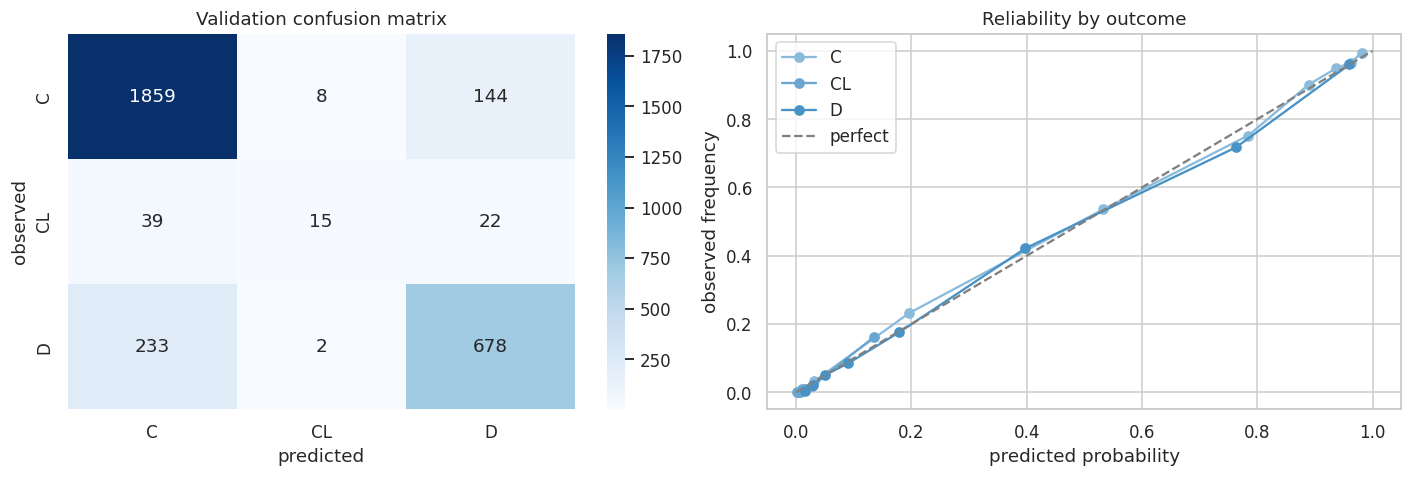

,feature,importance
2,Bilirubin,0.116413
10,Prothrombin,0.064298
0,N_Days,0.038873
1,Age,0.037541
5,Copper,0.015636
9,Platelets,0.014520
7,SGOT,0.013320
11,Stage,0.011719
8,Tryglicerides,0.006078
17,Edema,0.004633


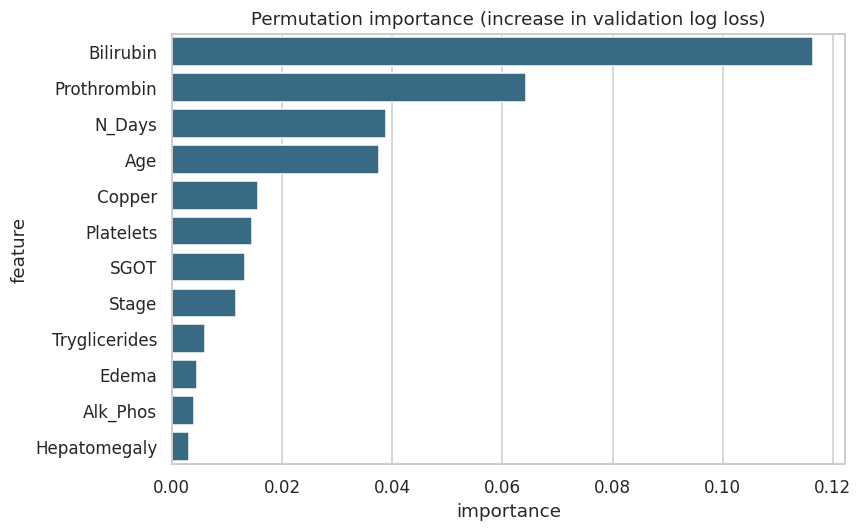

In [7]:
# --- Confusion matrix, reliability diagram and permutation importance.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cm = confusion_matrix(yv_str, np.array(config.CLASS_LABELS)[val_proba.argmax(axis=1)],
                      labels=config.CLASS_LABELS)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=config.CLASS_LABELS,
            yticklabels=config.CLASS_LABELS, ax=axes[0])
axes[0].set_title("Validation confusion matrix")
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("observed")

from sklearn.calibration import calibration_curve
for i, label in enumerate(config.CLASS_LABELS):
    prob_true, prob_pred = calibration_curve(
        (yv_str == label).astype(int), val_proba[:, i], n_bins=8, strategy="quantile")
    axes[1].plot(prob_pred, prob_true, marker="o", label=label)
axes[1].plot([0, 1], [0, 1], "--", color="grey", label="perfect")
axes[1].set_title("Reliability by outcome")
axes[1].set_xlabel("predicted probability"); axes[1].set_ylabel("observed frequency")
axes[1].legend()
fig.savefig(paths.FIGURES_DIR / "05_confusion_calibration.png", bbox_inches="tight")
plt.show()

importance = permutation_importance(eval_pipe, Xv, yv, n_repeats=5,
                                    random_state=SEED, scoring="neg_log_loss")
imp = pd.DataFrame({"feature": Xv.columns, "importance": importance.importances_mean})
imp = imp.sort_values("importance", ascending=False)
imp.to_csv(paths.IMPORTANCE_PATH, index=False)
display(imp.head(10))
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=imp.head(12), x="importance", y="feature", ax=ax, color="#2B6E8F")
ax.set_title("Permutation importance (increase in validation log loss)")
fig.savefig(paths.FIGURES_DIR / "05_feature_importance.png", bbox_inches="tight")
plt.show()

In [8]:
# --- Persist metadata with only real, measured values and build the submission.
import json
cv_row = bench[bench["model"] == best_name]
if "variant" in cv_row.columns:
    cv_row = cv_row[cv_row["variant"] == ("with_N_Days" if INCLUDE_N_DAYS else "without_N_Days")]
selected_cv = float(cv_row["log_loss"].iloc[0])
metadata = {
    "target": config.TARGET,
    "classes": config.CLASS_LABELS,
    "probability_columns": config.PROB_COLUMNS,
    "include_n_days": INCLUDE_N_DAYS,
    "n_labelled_rows": int(len(full_X)),
    "n_features_raw": len(config.RAW_FEATURES),
    "selected_model": best_name,
    "calibration_method": best_method,
    "cv_log_loss": selected_cv,
    "validation_log_loss": float(val_metrics["log_loss"]),
    "validation_accuracy": float(val_metrics["accuracy"]),
    "validation_f1_macro": float(val_metrics["f1_macro"]),
    "class_distribution": {k: int(v) for k, v in full_y.map({i: l for l, i in code.items()}).value_counts().items()},
    "ndays_ablation": comparison.to_dict(orient="records"),
    "calibration_comparison": val_results.to_dict(orient="records"),
    "seed": SEED,
}
with paths.METADATA_PATH.open("w") as fh:
    json.dump(metadata, fh, indent=2, default=str)

train, test_raw, template = data.load_raw()
submission = evaluation.build_submission(test_raw, template, final_pipe)
checks = evaluation.validate_submission(submission, template)
print("Submission checks:", checks)
assert checks["all_passed"]
submission.to_csv(paths.SUBMISSION_PATH, index=False)
print("Saved", paths.SUBMISSION_PATH, submission.shape)
display(submission.head())

Submission checks: {'columns_exact': True, 'row_count': True, 'ids_preserved': True, 'finite': True, 'non_negative': True, 'normalized': True, 'all_passed': True}
Saved /home/sabina/portfolio/cirrhosis/submission.csv (10000, 4)


,id,Status_C,Status_CL,Status_D
0,15000,0.352738,0.006851,0.640412
1,15001,0.873753,0.021126,0.105121
2,15002,0.830076,0.008490,0.161434
3,15003,0.985855,0.001246,0.012899
4,15004,0.330878,0.120202,0.548921


## Final decisions & limitations

- The with/without `N_Days` ablation and calibration comparison are saved as real CSV tables;
  the selected contract is recorded in `metadata.json` with its measured log loss.
- The final pipeline is pickled end-to-end (feature engineering → preprocessing → classifier),
  so serving cannot drift from training. It was refit on all labelled rows after selection.
- The holdout was evaluated once for selection; test probabilities are generated only at the end.
- These are statistical estimates from synthetic clinical data, not medical diagnoses.